# 02 · Language modeling and the bigram baseline

**Goal:** turn raw text into tensors, define what a language model actually
optimizes, and train the simplest one that works — a bigram model. It will be
bad, and *how* it is bad is precisely the motivation for attention.

**You will be able to:**
1. tokenize text and build `(x, y)` next-token training batches
2. state the training objective and read the loss in absolute terms
3. train a bigram language model in ~20 lines and sample from it
4. compute perplexity and explain what it means
5. articulate the bigram model's structural limitation

Prerequisite: notebook 01.

In [2]:
import math
import sys
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = Path.cwd()
if not (ROOT / "course_utils.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import course_utils as cu

cu.set_seed(1337)
device = cu.get_device()
print("device:", cu.describe_device(device))

device: cuda (NVIDIA GeForce RTX 2060)


## 1 · The corpus

`cu.get_text()` returns one long string. It tries `data/input.txt` first, then
downloads tiny-shakespeare (~1.1 MB), and if there is no network it writes a
deterministic synthetic play-script corpus so the notebook still runs. Drop
any UTF-8 text file at `data/input.txt` to use your own.

In [3]:
text = cu.get_text()
print(f"{len(text):,} characters")
print("-" * 60)
print(text[:400])

loaded 1,115,394 chars from C:\Users\harry\OneDrive\Desktop\transformers\data\input.txt
1,115,394 characters
------------------------------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


> **A note on the numbers you will see.** Every loss in this course depends on
> which corpus you ended up with. Tiny-shakespeare is genuinely hard (a good
> small model reaches ~1.5 nats/char); the synthetic fallback is repetitive and
> far easier (a small model can get under 0.5). Never compare a loss across
> corpora — compare models trained on the *same* data, which is what each
> notebook does.

## 2 · Tokenization, the character-level version

A model consumes integers, not characters. The mapping from text to integers
is the **tokenizer**. The simplest choice — one token per unique character —
gives a tiny vocabulary and no out-of-vocabulary problem, at the cost of very
long sequences. Notebook 06 replaces it with byte-pair encoding.

In [4]:
tok = cu.CharTokenizer(text)
print(tok)
print("alphabet:", "".join(tok.chars).replace("\n", "\\n"))

sample = "The king speaks"
ids = tok.encode(sample)
print("encode:", ids)
print("decode:", repr(tok.decode(ids)))
assert tok.decode(tok.encode(sample)) == sample     # round-trip

CharTokenizer(vocab_size=65)
alphabet: \n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
encode: [32, 46, 43, 1, 49, 47, 52, 45, 1, 57, 54, 43, 39, 49, 57]
decode: 'The king speaks'


### The tokenizer trade-off, quantified

In [5]:
n_chars = len(text)
n_words = len(text.split())
print(f"characters : {n_chars:>9,}  vocab {tok.vocab_size:>6,}")
print(f"words      : {n_words:>9,}  vocab {len(set(text.split())):>6,}")
print(f"\nchar-level sequences are ~{n_chars / n_words:.1f}x longer than word-level,")
print("and attention cost grows with the SQUARE of sequence length. That tension")
print("is why real models use subword tokenization (notebook 06).")

characters : 1,115,394  vocab     65
words      :   202,651  vocab 25,670

char-level sequences are ~5.5x longer than word-level,
and attention cost grows with the SQUARE of sequence length. That tension
is why real models use subword tokenization (notebook 06).


## 3 · Text as one long tensor, split into train and validation

We hold back the last 10% to detect memorization. A model can always reduce
training loss by memorizing; only validation loss tells you it learned
something transferable.

In [6]:
data = torch.tensor(tok.encode(text), dtype=torch.long)
train_data, val_data = cu.train_val_split(data, frac=0.9)
splits = {"train": train_data, "val": val_data}
print("all:", tuple(data.shape), "| train:", tuple(train_data.shape),
      "| val:", tuple(val_data.shape))
print("first 20 ids:", data[:20].tolist())

all: (1115394,) | train: (1003854,) | val: (111540,)
first 20 ids: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]


## 4 · The objective: predict the next token, at every position

Given a window of `block_size` tokens, the target is the *same window shifted
by one*. One window of length 8 therefore contains 8 training examples, with
contexts of length 1, 2, ..., 8. This is why transformer training is so
sample-efficient: every position supervises a prediction.

In [7]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    ctx = x[:t + 1]
    print(f"context {repr(tok.decode(ctx)):>22}  ->  target {tok.decode([y[t]])!r}")

context                    'F'  ->  target 'i'
context                   'Fi'  ->  target 'r'
context                  'Fir'  ->  target 's'
context                 'Firs'  ->  target 't'
context                'First'  ->  target ' '
context               'First '  ->  target 'C'
context              'First C'  ->  target 'i'
context             'First Ci'  ->  target 't'


### Batches: many random windows at once

`get_batch` samples `B` random start offsets and stacks the windows. Randomly
sampling offsets every step is a cheap stand-in for shuffling a dataset.

In [8]:
def get_batch(split_data, batch_size, block_size, device="cpu"):
    ix = torch.randint(len(split_data) - block_size - 1, (batch_size,))
    x = torch.stack([split_data[i:i + block_size] for i in ix])         # (B, T)
    y = torch.stack([split_data[i + 1:i + block_size + 1] for i in ix]) # (B, T)
    return x.to(device), y.to(device)


xb, yb = get_batch(train_data, batch_size=4, block_size=8)
print("x:", tuple(xb.shape), " y:", tuple(yb.shape))
print(xb)
print("x row 0:", repr(tok.decode(xb[0])), "-> y row 0:", repr(tok.decode(yb[0])))
print("\n(y is x shifted left by one, so y[:, t] is the answer for x[:, :t+1])")

x: (4, 8)  y: (4, 8)
tensor([[53, 59,  6,  1, 58, 56, 47, 40],
        [49, 43, 43, 54,  1, 47, 58,  1],
        [13, 52, 45, 43, 50, 53,  8,  0],
        [ 1, 39,  1, 46, 53, 59, 57, 43]])
x row 0: 'ou, trib' -> y row 0: 'u, tribu'

(y is x shifted left by one, so y[:, t] is the answer for x[:, :t+1])


## 5 · The bigram language model

The whole model is a lookup table of shape `(V, V)`: row `i` holds the logits
for "what token follows token `i`". `nn.Embedding` *is* that table, and
indexing it is the forward pass. Note what is absent: no dependence on
anything before the immediately preceding token.

In [9]:
class BigramLM(nn.Module):
    def __init__(self, vocab_size: int):
        super().__init__()
        # row i = logits over the whole vocabulary for "token after i"
        self.table = nn.Embedding(vocab_size, vocab_size)   # (V, V)

    def forward(self, idx, targets=None):
        logits = self.table(idx)                            # (B, T) -> (B, T, V)
        loss = None
        if targets is not None:
            V = logits.size(-1)
            loss = F.cross_entropy(logits.view(-1, V), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)                     # (B, T, V)
            logits = logits[:, -1, :] / temperature   # (B, V) — only last step
            probs = F.softmax(logits, dim=-1)         # (B, V)
            nxt = torch.multinomial(probs, num_samples=1)   # (B, 1)
            idx = torch.cat([idx, nxt], dim=1)        # (B, T+1)
        return idx


bigram = BigramLM(tok.vocab_size)
print(bigram)
print("parameters:", cu.human(cu.count_params(bigram)))

BigramLM(
  (table): Embedding(65, 65)
)
parameters: 4.22K


### Reading the loss before training

An untrained model knows nothing, so it should be about as good as guessing
uniformly: loss ~ `ln(V)`. **Always check this before training anything.** If
your untrained loss is wildly off, your loss wiring or your init is wrong.

It comes out slightly *above* `ln(V)` here because `nn.Embedding` initializes
from N(0, 1): the rows are not flat, they are confidently wrong, and confident
wrong answers cost more than uniform ones. Scaling the table down at init
(`* 0.01`) lands almost exactly on `ln(V)` — try it.

In [10]:
xb, yb = get_batch(train_data, 32, block_size)
_, loss0 = bigram(xb, yb)
print(f"initial loss  : {loss0.item():.4f}")
print(f"ln(V) = ln({tok.vocab_size}) : {math.log(tok.vocab_size):.4f}")

initial loss  : 4.6125
ln(V) = ln(65) : 4.1744


### Untrained sample: pure noise

In [11]:
start = torch.zeros((1, 1), dtype=torch.long)
print(repr(tok.decode(bigram.generate(start, 150)[0])))

"\nLixa,nswYZwLEPS'ptIZqOZJ$CA$zy-QTkeMk x.gQSFCLg!iW3fO!3DGXAqTsq3pdgq!LznIeJydZJSrFSrPLR!:VwWSmFNxbjPiNYQ:sry,OfKrxfvJI$WS3JqCbB-TSQXeKroeZfPL&,:opkl;B"


## 6 · Train it

In [12]:
bigram = BigramLM(tok.vocab_size).to(device)
opt = torch.optim.AdamW(bigram.parameters(), lr=1e-2)

history = {"step": [], "train": [], "val": [], "step_loss": []}
steps = 3000
for step in range(steps + 1):
    if step % 500 == 0:
        ev = cu.estimate_loss(bigram, splits, 64, block_size, device, iters=30)
        history["step"].append(step)
        history["train"].append(ev["train"])
        history["val"].append(ev["val"])
        print(f"step {step:5d} | train {ev['train']:.4f} | val {ev['val']:.4f}")
    if step == steps:
        break
    xb, yb = get_batch(train_data, 64, block_size, device)
    _, loss = bigram(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    history["step_loss"].append(loss.item())

step     0 | train 4.5253 | val 4.5469
step   500 | train 2.5305 | val 2.5562
step  1000 | train 2.4817 | val 2.5263
step  1500 | train 2.4767 | val 2.4958
step  2000 | train 2.4624 | val 2.5050
step  2500 | train 2.4649 | val 2.4930
step  3000 | train 2.4402 | val 2.4850


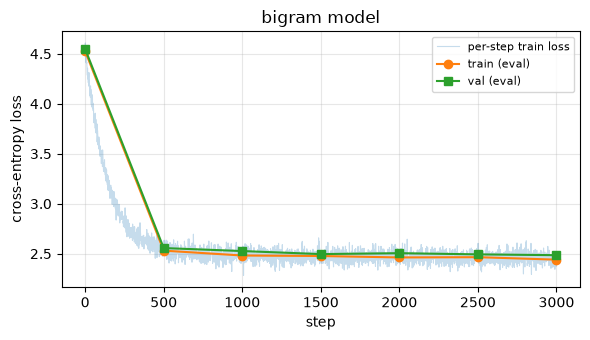

In [13]:
try:
    import matplotlib.pyplot as plt
    cu.plot_history(history, "bigram model")
    plt.tight_layout(); plt.show()
except ImportError:
    pass

## 7 · Interpreting the number

Loss is average `-log p(correct token)`, in nats. Two useful conversions:

- **bits per character** = loss / ln(2) — the compression rate the model achieves.
- **perplexity** = exp(loss) — "effectively how many equally-likely choices is
  the model picking between at each step".

A uniform model over 47 characters has perplexity 47. Getting to ~10 means the
model has genuinely narrowed the field, even with no notion of context.

In [14]:
final = history["val"][-1]
print(f"val loss      : {final:.4f} nats")
print(f"bits per char : {final / math.log(2):.4f}")
print(f"perplexity    : {math.exp(final):.2f}  (uniform baseline: {tok.vocab_size})")

val loss      : 2.4850 nats
bits per char : 3.5850
perplexity    : 12.00  (uniform baseline: 65)


### What the model learned, visualized

The learned table is a next-character transition matrix. Reading a row tells
you the model's entire belief given that character.

In [15]:
probs = F.softmax(bigram.table.weight.detach().cpu().float(), dim=-1)   # (V, V)
for ch in ["t", "h", "q", " "]:
    if ch not in tok.stoi:
        continue
    row = probs[tok.stoi[ch]]
    top = torch.topk(row, 5)
    pretty = ", ".join(f"{tok.itos[int(i)]!r}:{p:.2f}"
                       for p, i in zip(top.values, top.indices))
    print(f"after {ch!r:>4} -> {pretty}")

after  't' -> 'h':0.33, ' ':0.25, 'o':0.09, 'e':0.06, 'i':0.04
after  'h' -> 'e':0.35, 'a':0.20, 'i':0.13, 'o':0.11, ' ':0.09
after  'q' -> 'u':0.98, '3':0.00, 'S':0.00, 'o':0.00, 'c':0.00
after  ' ' -> 't':0.15, 'a':0.08, 's':0.07, 'h':0.07, 'm':0.06


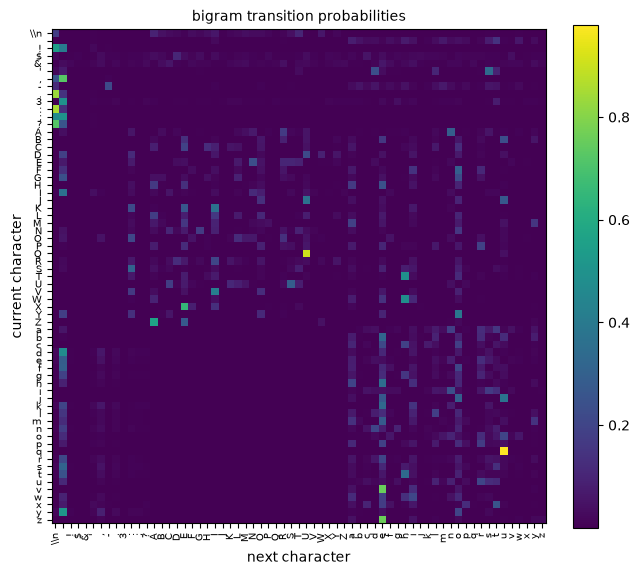

In [16]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 6))
    labels = [c.replace("\n", "\\n") for c in tok.chars]
    cu.show_attention(probs, tokens=labels, ax=ax,
                      title="bigram transition probabilities")
    ax.set_xlabel("next character"); ax.set_ylabel("current character")
    plt.tight_layout(); plt.show()
except ImportError:
    pass

## 8 · Sample from the trained model

In [17]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(repr(tok.decode(bigram.generate(start, 300, temperature=1.0)[0])))

'\n\n\nCExthy brid owindakis s, bth\n\nHAPen bube t e.\nS:\nO:\nIS:\nFalatanss:\nWantharun qur, vet?\nF dXENDoate awice my.\n\nHastacom oroup\nYowhthetof isth ble mil ndill, ath iree sengmin lat Herid ovets, and Win nghire yombousel lind me l.\nMAshe ce hiry:\nSupr aisspllw y.\nHerindu n Boopetelaves\nMP:\n\nPl, d methak'


Character *pairs* look plausible ("th", "he", " t"), and words are the right
length — but nothing survives beyond two characters. That is not a training
failure; it is the model class. `p(next | previous one token)` is all the
architecture can express.

## 9 · Temperature: the first decoding knob

Dividing logits by `T` before softmax reshapes the distribution:
`T < 1` sharpens it (safer, more repetitive), `T > 1` flattens it (more
surprising, more garbage). Notebook 12 covers top-k, nucleus sampling and
beam search.

In [18]:
for temperature in (0.3, 1.0, 1.8):
    out = bigram.generate(start, 120, temperature=temperature)[0]
    print(f"--- T={temperature} ---")
    print(repr(tok.decode(out)))

--- T=0.3 ---
'\n\n\n\n\nWhe t whe t the t the t there the the me s the the he the the hand t f th s the my t me there male the t the the the'
--- T=1.0 ---
"\nSo myr f-bube!\nKENob&isar adsal thes ghesthidin cour ay aney Iry ts I fr t ce.\nJO:\nNE:\nPAke mary.\nYof 'sour meam sora an"
--- T=1.8 ---
"\nIWie.-e?KENNORY: wnen.\nSand?; s-ze; ines th llugibod, TI'duco ffspy:\nsstatcas l.\nt\nIEiaspo tlupeinju.\nseazXIPewbe\nHalvev"


## 10 · Why we need something better

Extend the idea and the problem becomes obvious. An n-gram table needs `V**n`
parameters, so context length costs *exponentially*:

In [19]:
V = tok.vocab_size
for n in range(2, 8):
    print(f"{n}-gram table: V**{n} = {V ** n:>22,} parameters "
          f"({cu.human(V ** n)})")
print("\nA transformer with a 256-token context uses ~10M parameters total.")

2-gram table: V**2 =                  4,225 parameters (4.22K)
3-gram table: V**3 =                274,625 parameters (274.62K)
4-gram table: V**4 =             17,850,625 parameters (17.85M)
5-gram table: V**5 =          1,160,290,625 parameters (1.16B)
6-gram table: V**6 =         75,418,890,625 parameters (75.42B)
7-gram table: V**7 =      4,902,227,890,625 parameters (4902.23B)

A transformer with a 256-token context uses ~10M parameters total.


Concretely, here is a prediction no bigram can ever make. In the string
`"the king ... the k"`, the right continuation depends on tokens *far* back,
but the bigram sees only `"k"`. We need a model where a prediction can depend
on **all** previous tokens, with a parameter count that grows gently — and
where which earlier tokens matter is *learned*, not fixed.

That mechanism is attention.

In [20]:
ctx = "the k"
idx = torch.tensor([tok.encode(ctx)], device=device)
logits, _ = bigram(idx)
top = torch.topk(F.softmax(logits[0, -1], dim=-1), 4)
print(f"bigram, given {ctx!r} (it only looks at 'k'):")
print("  ", ", ".join(f"{tok.itos[int(i)]!r}:{p:.2f}"
                      for p, i in zip(top.values, top.indices)))

bigram, given 'the k' (it only looks at 'k'):
   'e':0.33, ' ':0.20, 'i':0.14, 'n':0.08


## Exercises

1. **Count, don't learn.** Build the bigram probability table by *counting*
   transitions in `train_data` (add-one smoothing), and compare its validation
   loss to the trained model's. Why are they so close?
2. **Block size sweep.** Train the bigram at `block_size` 4, 8, 64. Explain why
   the loss barely changes, unlike what you'd expect from a transformer.
3. **Trigram.** Implement a trigram model by embedding the *pair* of previous
   tokens (`idx[:, :-1] * V + idx[:, 1:]` as the lookup index). How much does
   validation loss improve, and how many parameters did it cost?
4. **Perplexity by hand.** Write `perplexity(model, data)` that iterates over
   non-overlapping windows of the validation set and returns `exp(mean loss)`.
5. **Your own corpus.** Put a text file at `data/input.txt`, re-run, and
   compare `ln(V)` against the final loss for your alphabet.

---
**Next:** [03 · Attention from scratch](03_attention_from_scratch.ipynb) — build
self-attention one tensor at a time, starting from a plain average.

In [21]:
import torch
import torch.nn.functional as F

def build_count_bigram(train_data, vocab_size):
    # 1. Initialize a 2D matrix of zeros
    counts = torch.zeros((vocab_size, vocab_size), dtype=torch.float)
    
    # 2. Count the transitions (bigrams) sequence by sequence
    # train_data is assumed to be a 1D tensor of token IDs
    inputs = train_data[:-1]
    targets = train_data[1:]
    
    # Efficient scatter-add for counting in PyTorch
    counts.index_put_((inputs, targets), torch.ones_like(inputs, dtype=torch.float), accumulate=True)
    
    # 3. Apply Laplace (Add-One) smoothing to avoid 0 probabilities
    counts += 1.0
    
    # 4. Normalize rows into probabilities (each row sums to 1.0)
    prob_table = counts / counts.sum(dim=-1, keepdim=True)
    
    return prob_table

# Evaluation function for the count table
def evaluate_count_model(prob_table, val_data):
    val_inputs = val_data[:-1]
    val_targets = val_data[1:]
    
    # Extract matching transition probabilities and take the negative log likelihood
    val_probs = prob_table[val_inputs, val_targets]
    val_loss = -torch.log(val_probs).mean()
    return val_loss.item()


prob_table = build_count_bigram(train_data, tok.vocab_size)

# 1. Align validation inputs and targets
val_inputs = val_data[:-1]
val_targets = val_data[1:]

# 2. Look up the transition probabilities from your count table
val_probs = prob_table[val_inputs, val_targets]

# 3. Calculate negative log-likelihood (Cross-Entropy equivalent)
count_val_loss = -torch.log(val_probs).mean().item()

print(f"Count Table Validation Loss: {count_val_loss:.4f}")

Count Table Validation Loss: 2.4819


In [22]:

for block_size in [4, 8, 64]:
    bigram = BigramLM(tok.vocab_size).to(device)
    opt = torch.optim.AdamW(bigram.parameters(), lr=1e-2)
    history = {"step": [], "train": [], "val": [], "step_loss": []}
    steps = 3000
    opt.zero_grad(set_to_none=True)
    for step in range(steps + 1):
        if step == steps:
            break
        xb, yb = get_batch(train_data, 64, block_size, device)
        _, loss = bigram(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    xv, yv = get_batch(val_data, 64, block_size, device)
    _, val_loss = bigram(xv, yv)
    print(f"block_size {block_size} val loss: {val_loss}")

block_size 4 val loss: 2.5749728679656982
block_size 8 val loss: 2.530839443206787
block_size 64 val loss: 2.451631784439087


In [23]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class TrigramLM(nn.Module): 
    def __init__(self, vocab_size: int, device: str = 'cpu'): 
        super().__init__() 
        self.V = vocab_size
        self.device = device # Track the active execution device
        
        # Explicitly build the table directly on the correct hardware target
        self.table = nn.Embedding(vocab_size * vocab_size, vocab_size, device=device) 
        
    def forward(self, idx, targets=None): 
        B, T = idx.shape
        
        # Guard rail: Use the explicit device tracking parameter to avoid CPU/GPU splits
        if T < 2:
            logits = torch.zeros((B, T, self.V), device=self.device)
            dummy_loss = torch.tensor(0.0, device=self.device)
            return logits, dummy_loss if targets is not None else None

        # Extract history sequences
        c1 = idx[:, :-1] 
        c2 = idx[:, 1:]  
        
        # Flattening indices cleanly matches the device footprint of the parent tensor
        lookup_index = c1 * self.V + c2 
        
        # Lookup logits
        logits = self.table(lookup_index) # Shape: (B, T-1, V)
        
        loss = None 
        if targets is not None: 
            # Align targets to slice window
            aligned_targets = targets[:, 1:] 
            
            V = logits.size(-1) 
            loss = F.cross_entropy(logits.reshape(-1, V), aligned_targets.reshape(-1))
        return logits, loss

    @torch.no_grad() 
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0): 
        for _ in range(max_new_tokens): 
            context = idx[:, -2:]
            logits, _ = self(context) 
            logits = logits[:, -1, :] / temperature 
            probs = F.softmax(logits, dim=-1) 
            nxt = torch.multinomial(probs, num_samples=1) 
            idx = torch.cat([idx, nxt], dim=1) 
        return idx



trigram = TrigramLM(tok.vocab_size, device=device)
print(trigram)
print("parameters:", cu.human(cu.count_params(trigram)))

TrigramLM(
  (table): Embedding(4225, 65)
)
parameters: 274.62K


step     0 | train 4.6832 | val 4.6712
step   500 | train 2.0623 | val 2.1748
step  1000 | train 1.9474 | val 2.0785
step  1500 | train 1.9360 | val 2.0665
step  2000 | train 1.9258 | val 2.0554
step  2500 | train 1.9173 | val 2.0629
step  3000 | train 1.9176 | val 2.0572


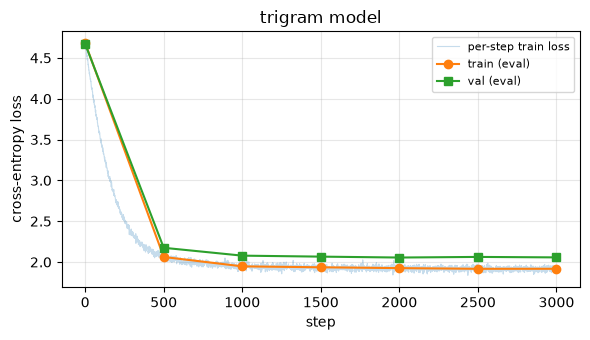

val loss      : 2.0572 nats
bits per char : 2.9679
perplexity    : 7.82  (uniform baseline: 65)


In [24]:
opt = torch.optim.AdamW(trigram.parameters(), lr=1e-2)

history = {"step": [], "train": [], "val": [], "step_loss": []}
steps = 3000
for step in range(steps + 1):
    if step % 500 == 0:
        ev = cu.estimate_loss(trigram, splits, 64, block_size, device, iters=30)
        history["step"].append(step)
        history["train"].append(ev["train"])
        history["val"].append(ev["val"])
        print(f"step {step:5d} | train {ev['train']:.4f} | val {ev['val']:.4f}")
    if step == steps:
        break
    xb, yb = get_batch(train_data, 64, block_size, device)
    _, loss = trigram(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    history["step_loss"].append(loss.item())


try:
    import matplotlib.pyplot as plt
    cu.plot_history(history, "trigram model")
    plt.tight_layout(); plt.show()
except ImportError:
    pass


final = history["val"][-1]
print(f"val loss      : {final:.4f} nats")
print(f"bits per char : {final / math.log(2):.4f}")
print(f"perplexity    : {math.exp(final):.2f}  (uniform baseline: {tok.vocab_size})")

In [25]:




    
with open(f"{ROOT}/data/input.txt", "r") as file:
    text = file.read()



block_size = 30


data = torch.tensor(tok.encode(text), dtype=torch.long)
train_data, val_data = cu.train_val_split(data, frac=0.9)


trigram = TrigramLM(tok.vocab_size, device=device)



opt = torch.optim.AdamW(trigram.parameters(), lr=1e-2)

steps = 3000
for step in range(steps + 1):
    if step == steps:
        break
    xb, yb = get_batch(train_data, 64, block_size, device)
    _, loss = trigram(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()



xb, yb = get_batch(data, 32, block_size, device)
_, loss0 = trigram(xb, yb)


print(f"initial loss  : {loss0.item():.4f}")
print(f"ln(V) = ln({tok.vocab_size}) : {math.log(tok.vocab_size):.4f}")

initial loss  : 1.8629
ln(V) = ln(65) : 4.1744
